# Activity: Model training and evaluation
## Linear regression, logistic regression, decision tree, and clustering
#Data mining
#Nelsy Madera
In the previous activity, an Exploratory Data Analysis (EDA) was carried out and the differences between supervised and unsupervised learning were studied. For this activity, the same synthetic health dataset will be used to go through a basic modeling workflow:

1. Define a question and a target variable.
2. Split training and test data.
3. Prepare numerical and categorical variables.
4. Train representative models.
5. Evaluate their results with appropriate metrics.
6. Interpret confusion matrices.
7. Create and describe groups with clustering.

> The dataset is synthetic and is used for educational purposes only. The results are not clinical criteria or recommendations.

> **Note:** This notebook was made with the help of Claude Ia.

## Learning outcomes

By the end of the activity you will be able to:

- Differentiate between regression, classification, and clustering tasks.
- Prepare data through imputation, encoding, and scaling.
- Train a linear regression, a logistic regression, and a decision tree.
- Interpret MAE, RMSE, and $R^2$ in regression.
- Interpret accuracy, precision, recall, and F1-score in classification.
- Read a multiclass confusion matrix.
- Choose a number of clusters using inertia and the silhouette score.
- Compare models without assuming that a single metric tells the whole story.

## How the activity is organized

| Block | Learning type | Question | Main model | Evaluation |
|---|---|---|---|---|
| A | Supervised: regression | Can we estimate a continuous value? | Linear regression | MAE, RMSE, and $R^2$ |
| B | Supervised: classification | Can we predict a category? | Logistic regression | Accuracy, precision, recall, F1, and confusion matrix |
| C | Supervised: classification | Can we obtain decision rules? | Decision tree | The same metrics and comparison with logistic regression |
| D | Unsupervised | Are there natural profiles in the data? | K-means | Inertia, silhouette, and cluster profile |

Each block combines guided code, results, and interpretation questions. Complete the answers in new text cells below each activity.

# 1. Environment setup

If you work in an environment that does not have the libraries installed, run the following instruction once, removing the `#` symbol:

`# %pip install pandas numpy matplotlib seaborn openpyxl scikit-learn`

In [3]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
    silhouette_score,
)
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11

SEMILLA = 42


## 1.1 Loading the dataset

In [4]:
rutas_posibles = [
    Path("Dataset_Sintetico_Salud_.xlsx"),
    Path("Dataset_Sintetico_Salud_EDA.xlsx"),
    Path("outputs/actividad_eda_salud/Dataset_Sintetico_Salud_EDA.xlsx"),
    Path("../actividad_eda_salud/Dataset_Sintetico_Salud_EDA.xlsx"),
]

ruta_datos = next((ruta for ruta in rutas_posibles if ruta.exists()), None)
if ruta_datos is None:
    raise FileNotFoundError(
        "File Dataset_Sintetico_Salud_.xlsx not found. "
        "Place it next to the notebook or adjust the path."
    )

df_original = pd.read_excel(ruta_datos, sheet_name="Datos")
df_original["Mes_Registro"] = pd.to_datetime(df_original["Mes_Registro"])

print(f"File: {ruta_datos}")
print(f"Original dimensions: {df_original.shape[0]} rows and {df_original.shape[1]} columns")
df_original.head()


File: Dataset_Sintetico_Salud_.xlsx
Original dimensions: 500 rows and 14 columns


,ID_Paciente,Mes_Registro,Edad,Genero,IMC,Glucosa_mg_dL,Presion_Sistolica_mmHg,Colesterol_mg_dL,Actividad_Fisica,Fumador,Horas_Sueno,Nivel_Estres,Consultas_Medicas,Nivel_Riesgo
0,PAC-0001,2025-08-01,33,Masculino,21.6,70.0,110,149.0,Alta,No,6.5,6,0,Bajo
1,PAC-0002,2025-03-01,56,Femenino,33.8,129.0,130,171.0,Baja,No,6.8,5,0,Alto
2,PAC-0003,2025-03-01,57,Masculino,25.0,95.0,129,208.0,Moderada,Sí,5.8,8,6,Medio
3,PAC-0004,2025-11-01,68,Masculino,28.2,95.0,125,253.0,Moderada,No,7.3,6,5,Medio
4,PAC-0005,2025-02-01,47,Masculino,28.5,111.0,129,192.0,Alta,Sí,6.8,7,0,Medio


## 1.2 Quick check before modeling

In [5]:
resumen_calidad = pd.DataFrame({
    "dtype": df_original.dtypes.astype(str),
    "nulls": df_original.isna().sum(),
    "null_percentage": (df_original.isna().mean() * 100).round(2),
    "unique": df_original.nunique(dropna=True),
})

print(f"Exact duplicates: {df_original.duplicated().sum()}")
print("Distribution of Nivel_Riesgo:")
print(df_original["Nivel_Riesgo"].value_counts())
resumen_calidad


Exact duplicates: 3
Distribution of Nivel_Riesgo:
Nivel_Riesgo
Medio    196
Bajo     170
Alto     134
Name: count, dtype: int64


,dtype,nulls,null_percentage,unique
ID_Paciente,object,0,0.0,497
Mes_Registro,datetime64[ns],0,0.0,12
Edad,int64,0,0.0,65
Genero,object,0,0.0,3
IMC,float64,5,1.0,168
Glucosa_mg_dL,float64,6,1.2,82
Presion_Sistolica_mmHg,int64,0,0.0,66
Colesterol_mg_dL,float64,3,0.6,124
Actividad_Fisica,object,4,0.8,3
Fumador,object,0,0.0,2


### Preparation decisions

- We will remove exact duplicates before splitting the data. This prevents one copy of the same observation from ending up in training and another in test.
- We will not remove rows just because they have null values. We will handle them inside the pipelines through imputation.
- `ID_Paciente` is not an explanatory feature and will not be used as a predictor.
- We will transform the month into a number from 1 to 12 when useful.
- We will keep the possible outliers to observe how they affect performance.

In [6]:
df = df_original.drop_duplicates().copy()
df["Mes_Numero"] = df["Mes_Registro"].dt.month

print(f"Rows available after removing duplicates: {len(df)}")


Rows available after removing duplicates: 497


## Activity 1. Suitability of the dataset

Answer before training:

1. Which variable would you use as the target for a classification?
2. Which continuous variable could be used as the target of a regression?
3. Why should `ID_Paciente` not be used as a predictor?
4. Why should `Nivel_Riesgo` not be included among the clustering variables?
5. What risk would there be if we kept the duplicate records before splitting the data?

**Answers — Activity 1**
1. Classification target: `Nivel_Riesgo` (risk level).
2. Regression target: `Glucosa_mg_dL` (glucose).
3. `ID_Paciente` only identifies the record; it carries no explanatory information.
4. K-means is unsupervised: the label should not guide the groups.
5. One copy could land in the training set and another in the test set (data leakage), inflating the metrics.

# 2. Block A: linear regression

## Modeling question

**Can we estimate glucose (`Glucosa_mg_dL`) from other available characteristics?**

This is a regression task because the target variable is numeric and continuous. We will not use `Nivel_Riesgo` as a predictor because it was built from clinical variables, including glucose, and it would produce a circular relationship in this didactic exercise.

In [7]:
objetivo_reg = "Glucosa_mg_dL"

variables_reg = [
    "Edad",
    "Genero",
    "IMC",
    "Presion_Sistolica_mmHg",
    "Colesterol_mg_dL",
    "Actividad_Fisica",
    "Fumador",
    "Horas_Sueno",
    "Nivel_Estres",
    "Consultas_Medicas",
    "Mes_Numero",
]

categoricas_reg = ["Genero", "Actividad_Fisica", "Fumador"]
numericas_reg = [columna for columna in variables_reg if columna not in categoricas_reg]

df_reg = df.dropna(subset=[objetivo_reg]).copy()
X_reg = df_reg[variables_reg]
y_reg = df_reg[objetivo_reg]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg,
    y_reg,
    test_size=0.25,
    random_state=SEMILLA,
)

print("Training:", Xr_train.shape)
print("Test:", Xr_test.shape)


Training: (368, 11)
Test: (123, 11)


## 2.1 Preparation and training pipeline

The pipeline avoids manually preparing training and test sets separately:

- numerical variables: median + scaling;
- categorical variables: most frequent category + one-hot encoding;
- final model: linear regression.

In [8]:
preprocesador_reg = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline(
                steps=[
                    ("imputation", SimpleImputer(strategy="median")),
                    ("scaling", StandardScaler()),
                ]
            ),
            numericas_reg,
        ),
        (
            "cat",
            Pipeline(
                steps=[
                    ("imputation", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            categoricas_reg,
        ),
    ]
)

modelo_lineal = Pipeline(
    steps=[
        ("preprocessing", preprocesador_reg),
        ("model", LinearRegression()),
    ]
)

modelo_lineal.fit(Xr_train, yr_train)
pred_reg = modelo_lineal.predict(Xr_test)


## 2.2 Regression metrics

In [9]:
metricas_regresion = pd.Series({
    "MAE": mean_absolute_error(yr_test, pred_reg),
    "RMSE": np.sqrt(mean_squared_error(yr_test, pred_reg)),
    "R2": r2_score(yr_test, pred_reg),
}).round(3)

metricas_regresion


,0
MAE,12.446
RMSE,15.254
R2,0.170


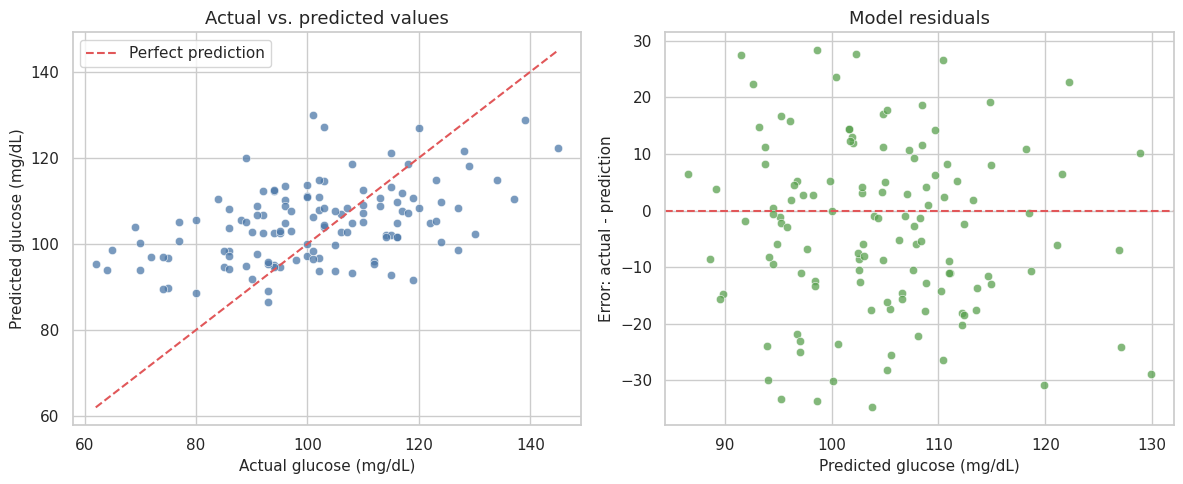

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.scatterplot(x=yr_test, y=pred_reg, ax=axes[0], color="#4C78A8", alpha=0.75)
limites = [min(yr_test.min(), pred_reg.min()), max(yr_test.max(), pred_reg.max())]
axes[0].plot(limites, limites, "--", color="#E15759", label="Perfect prediction")
axes[0].set(
    title="Actual vs. predicted values",
    xlabel="Actual glucose (mg/dL)",
    ylabel="Predicted glucose (mg/dL)",
)
axes[0].legend()

residuos = yr_test.to_numpy() - pred_reg
sns.scatterplot(x=pred_reg, y=residuos, ax=axes[1], color="#59A14F", alpha=0.75)
axes[1].axhline(0, linestyle="--", color="#E15759")
axes[1].set(
    title="Model residuals",
    xlabel="Predicted glucose (mg/dL)",
    ylabel="Error: actual - prediction",
)

plt.tight_layout()
plt.show()


## Activity 2. Interpreting the regression

1. Interpret the MAE in the same units as glucose.
2. Why is the RMSE usually larger than the MAE?
3. What does the obtained $R^2$ value mean?
4. Are the points concentrated near the perfect-prediction line?
5. Do the residuals look random or do they show a pattern?
6. Based on the metrics, would you use this model as the final model? Justify.

**Important:** a modest result is also a valid result. Evaluation serves to recognize the model's limitations and decide what to improve.

**Answers — Activity 2** (MAE 12.446 · RMSE 15.254 · R² 0.170)
1. On average, the prediction is off by about 12.4 mg/dL.
2. RMSE penalizes large errors more heavily; 15.25 vs. 12.45 indicates some large errors.
3. The model explains only about 17% of the variability in glucose.
4. No: predictions are concentrated in a narrow range (≈87–130) compared with real values of ≈62–145.
5. Residuals look random and centered near zero, with some errors of ±30.
6. Not as a final model; it works as a baseline.

# 3. Block B: logistic regression for classification

## Modeling question

**Can we predict `Nivel_Riesgo` as Bajo (Low), Medio (Medium), or Alto (High)?**

Although its name contains the word *regression*, logistic regression is used for classification. In this case we will work with three classes.

In [11]:
objetivo_clas = "Nivel_Riesgo"

variables_clas = [
    "Edad",
    "Genero",
    "IMC",
    "Glucosa_mg_dL",
    "Presion_Sistolica_mmHg",
    "Colesterol_mg_dL",
    "Actividad_Fisica",
    "Fumador",
    "Horas_Sueno",
    "Nivel_Estres",
    "Consultas_Medicas",
    "Mes_Numero",
]

categoricas_clas = ["Genero", "Actividad_Fisica", "Fumador"]
numericas_clas = [columna for columna in variables_clas if columna not in categoricas_clas]

X_clas = df[variables_clas]
y_clas = df[objetivo_clas]

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_clas,
    y_clas,
    test_size=0.25,
    random_state=SEMILLA,
    stratify=y_clas,
)

print("Distribution in training:")
print(yc_train.value_counts(normalize=True).round(3))
print("\nDistribution in test:")
print(yc_test.value_counts(normalize=True).round(3))


Distribution in training:
Nivel_Riesgo
Medio    0.395
Bajo     0.339
Alto     0.266
Name: proportion, dtype: float64

Distribution in test:
Nivel_Riesgo
Medio    0.392
Bajo     0.344
Alto     0.264
Name: proportion, dtype: float64


In [12]:
def crear_preprocesador_clasificacion():
    return ColumnTransformer(
        transformers=[
            (
                "num",
                Pipeline(
                    steps=[
                        ("imputation", SimpleImputer(strategy="median")),
                        ("scaling", StandardScaler()),
                    ]
                ),
                numericas_clas,
            ),
            (
                "cat",
                Pipeline(
                    steps=[
                        ("imputation", SimpleImputer(strategy="most_frequent")),
                        ("onehot", OneHotEncoder(handle_unknown="ignore")),
                    ]
                ),
                categoricas_clas,
            ),
        ]
    )


def calcular_metricas_clasificacion(y_real, y_pred):
    return {
        "Accuracy": accuracy_score(y_real, y_pred),
        "Precision_macro": precision_score(y_real, y_pred, average="macro", zero_division=0),
        "Recall_macro": recall_score(y_real, y_pred, average="macro", zero_division=0),
        "F1_macro": f1_score(y_real, y_pred, average="macro", zero_division=0),
    }


In [13]:
modelo_logistico = Pipeline(
    steps=[
        ("preprocessing", crear_preprocesador_clasificacion()),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=SEMILLA,
            ),
        ),
    ]
)

modelo_logistico.fit(Xc_train, yc_train)
pred_logistica = modelo_logistico.predict(Xc_test)

metricas_logistica = calcular_metricas_clasificacion(yc_test, pred_logistica)
pd.Series(metricas_logistica).round(3)


,0
Accuracy,0.856
Precision_macro,0.858
Recall_macro,0.862
F1_macro,0.859


## 3.1 Classification report

In [14]:
reporte_logistica = pd.DataFrame(
    classification_report(
        yc_test,
        pred_logistica,
        labels=["Bajo", "Medio", "Alto"],
        output_dict=True,
        zero_division=0,
    )
).T

reporte_logistica.round(3)


,precision,recall,f1-score,support
Bajo,0.925,0.860,0.892,43.000
Medio,0.816,0.816,0.816,49.000
Alto,0.833,0.909,0.870,33.000
accuracy,0.856,0.856,0.856,0.856
macro avg,0.858,0.862,0.859,125.000
weighted avg,0.858,0.856,0.856,125.000


## 3.2 Confusion matrix

In the confusion matrix:

- rows represent the actual classes;
- columns represent the predicted classes;
- the diagonal contains the correct predictions;
- the cells off the diagonal show the types of error.

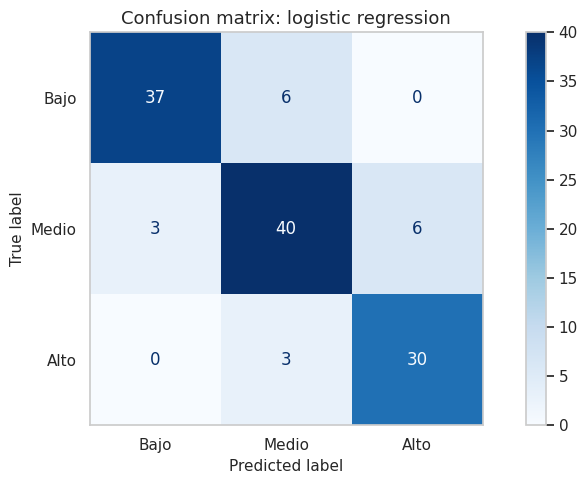

In [15]:
orden_clases = ["Bajo", "Medio", "Alto"]
matriz_logistica = confusion_matrix(yc_test, pred_logistica, labels=orden_clases)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_logistica,
    display_labels=orden_clases,
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix: logistic regression")
plt.grid(False)
plt.tight_layout()
plt.show()


## Activity 3. Reading the confusion matrix

1. How many records were classified correctly?
2. Which class had the highest recall?
3. Which confusion was most frequent: Bajo-Medio, Medio-Alto, or Bajo-Alto?
4. Why might a misclassification between neighboring categories be interpreted differently from a confusion between Bajo and Alto?
5. Explain in your own words the difference between precision and recall.
6. What does the F1-score add compared with looking at precision or recall separately?

**Answers — Activity 3**
1. 107 out of 125 correct (accuracy 0.856).
2. Highest recall: **Alto** (High), 30/33 = 0.909.
3. Bajo–Medio and Medio–Alto tie with 9 errors each; Bajo–Alto, 0.
4. Errors between neighboring levels are less serious than confusing Bajo (Low) with Alto (High), which is two levels apart.
5. Precision: of the cases predicted as a class, how many were correct. Recall: of the cases that truly belong to a class, how many were detected.
6. F1 combines precision and recall and drops if either one is low.

# 4. Block C: decision tree

The decision tree splits the data through successive rules. It is easy to explain, allows nonlinear relationships, and does not require the variables to be linearly related. Without depth control it can memorize the training data and overfit.

In [16]:
modelo_arbol = Pipeline(
    steps=[
        ("preprocessing", crear_preprocesador_clasificacion()),
        (
            "model",
            DecisionTreeClassifier(
                max_depth=5,
                min_samples_leaf=8,
                class_weight="balanced",
                random_state=SEMILLA,
            ),
        ),
    ]
)

modelo_arbol.fit(Xc_train, yc_train)
pred_arbol = modelo_arbol.predict(Xc_test)

metricas_arbol = calcular_metricas_clasificacion(yc_test, pred_arbol)
pd.Series(metricas_arbol).round(3)


,0
Accuracy,0.680
Precision_macro,0.708
Recall_macro,0.674
F1_macro,0.685


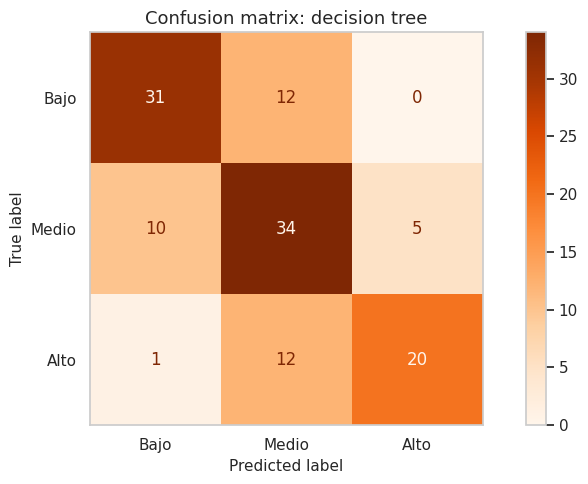

In [17]:
matriz_arbol = confusion_matrix(yc_test, pred_arbol, labels=orden_clases)

disp = ConfusionMatrixDisplay(
    confusion_matrix=matriz_arbol,
    display_labels=orden_clases,
)
disp.plot(cmap="Oranges", values_format="d")
plt.title("Confusion matrix: decision tree")
plt.grid(False)
plt.tight_layout()
plt.show()


## 4.1 Variable importance

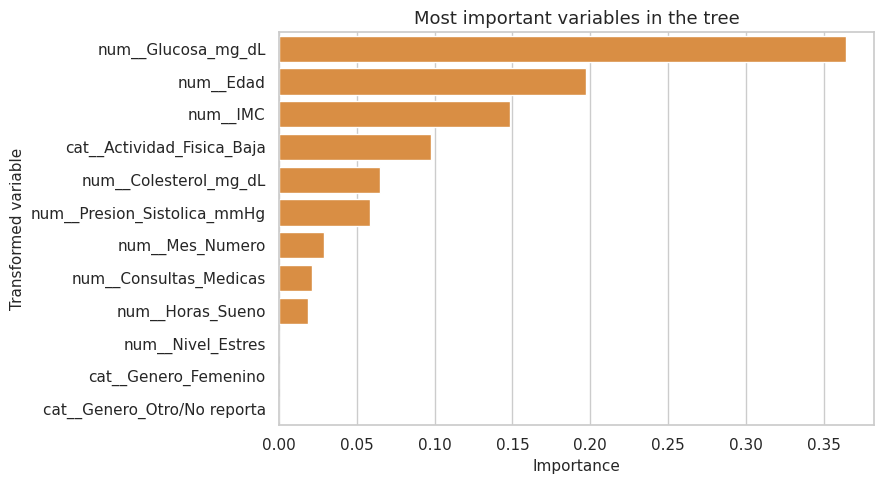

,0
num__Glucosa_mg_dL,0.364
num__Edad,0.197
num__IMC,0.148
cat__Actividad_Fisica_Baja,0.098
num__Colesterol_mg_dL,0.065
num__Presion_Sistolica_mmHg,0.058
num__Mes_Numero,0.029
num__Consultas_Medicas,0.022
num__Horas_Sueno,0.019
num__Nivel_Estres,0.000


In [18]:
preprocesador_entrenado = modelo_arbol.named_steps["preprocessing"]
arbol_entrenado = modelo_arbol.named_steps["model"]
nombres_variables = preprocesador_entrenado.get_feature_names_out()

importancias = (
    pd.Series(arbol_entrenado.feature_importances_, index=nombres_variables)
    .sort_values(ascending=False)
    .head(12)
)

ax = sns.barplot(x=importancias.values, y=importancias.index, color="#F28E2B")
ax.set(
    title="Most important variables in the tree",
    xlabel="Importance",
    ylabel="Transformed variable",
)
plt.tight_layout()
plt.show()

importancias.round(3)


## 4.2 Partial visualization of the tree

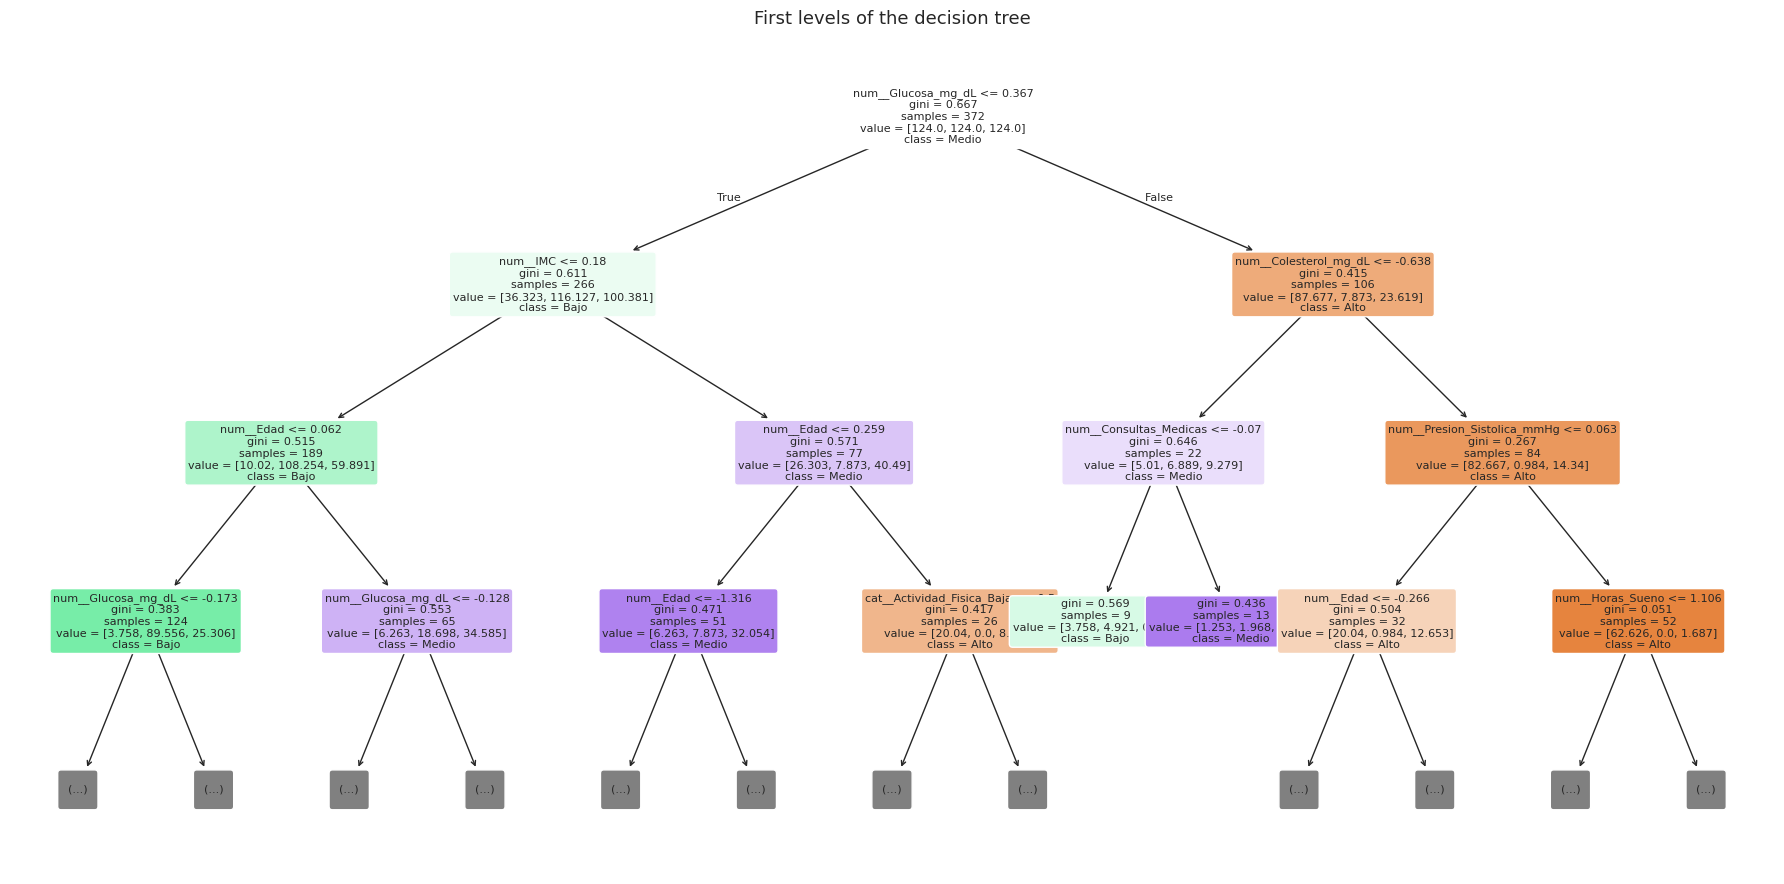

In [19]:
plt.figure(figsize=(18, 9))
plot_tree(
    arbol_entrenado,
    feature_names=nombres_variables,
    class_names=[str(clase) for clase in arbol_entrenado.classes_],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8,
)
plt.title("First levels of the decision tree")
plt.tight_layout()
plt.show()


The image shows only the first levels to keep it readable. Follow a path from the root to a leaf and explain which conditions apply and which class is predicted.

## 4.3 Depth and overfitting

In [20]:
resultados_profundidad = []

for profundidad in [2, 3, 5, 8, None]:
    modelo_prueba = Pipeline(
        steps=[
            ("preprocessing", crear_preprocesador_clasificacion()),
            (
                "model",
                DecisionTreeClassifier(
                    max_depth=profundidad,
                    min_samples_leaf=4,
                    class_weight="balanced",
                    random_state=SEMILLA,
                ),
            ),
        ]
    )
    modelo_prueba.fit(Xc_train, yc_train)
    resultados_profundidad.append({
        "max_depth": "No limit" if profundidad is None else str(profundidad),
        "accuracy_train": modelo_prueba.score(Xc_train, yc_train),
        "accuracy_test": modelo_prueba.score(Xc_test, yc_test),
    })

tabla_profundidad = pd.DataFrame(resultados_profundidad)
tabla_profundidad.round(3)


,max_depth,accuracy_train,accuracy_test
0,2,0.632,0.624
1,3,0.718,0.656
2,5,0.839,0.688
3,8,0.884,0.624
4,No limit,0.882,0.640


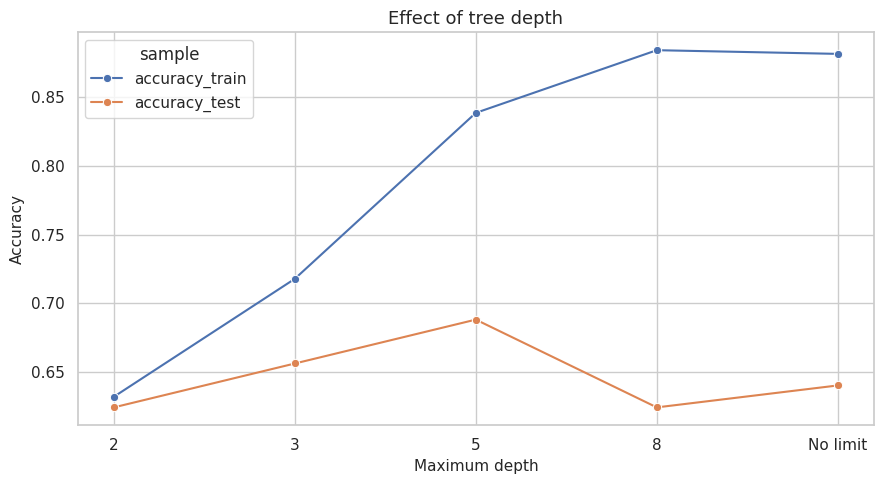

In [21]:
tabla_larga = tabla_profundidad.melt(
    id_vars="max_depth",
    value_vars=["accuracy_train", "accuracy_test"],
    var_name="sample",
    value_name="accuracy",
)

ax = sns.lineplot(
    data=tabla_larga,
    x="max_depth",
    y="accuracy",
    hue="sample",
    marker="o",
)
ax.set(
    title="Effect of tree depth",
    xlabel="Maximum depth",
    ylabel="Accuracy",
)
plt.tight_layout()
plt.show()


## Activity 4. Interpreting the tree

1. Which variables had the highest importance?
2. Does importance indicate causality? Explain.
3. Compare the confusion matrices of the tree and logistic regression.
4. What happens to the training accuracy as depth increases?
5. At what point does an important gap between training and test appear?
6. Which depth would you choose and why?

**Answers — Activity 4**
1. Glucose (0.364), age (0.197), BMI (0.148), and low physical activity (0.098).
2. No: importance measures how much the tree used a variable to split, not causality.
3. The tree gets 85/125 right vs. 107/125 for logistic regression, and labels 12 Alto (High) cases as Medio (Medium).
4. It increases with depth: 0.632 → 0.884.
5. The train–test gap becomes important from depth 5 (≈0.15).
6. Depth 3: small gap (0.718 vs. 0.656) and a simpler tree.

# 5. Comparison of the classification models

In [22]:
comparacion_clasificadores = pd.DataFrame(
    [
        {"Model": "Logistic regression", **metricas_logistica},
        {"Model": "Decision tree", **metricas_arbol},
    ]
).set_index("Model")

comparacion_clasificadores.round(3)


,Accuracy,Precision_macro,Recall_macro,F1_macro
Model,,,,
Logistic regression,0.856,0.858,0.862,0.859
Decision tree,0.680,0.708,0.674,0.685


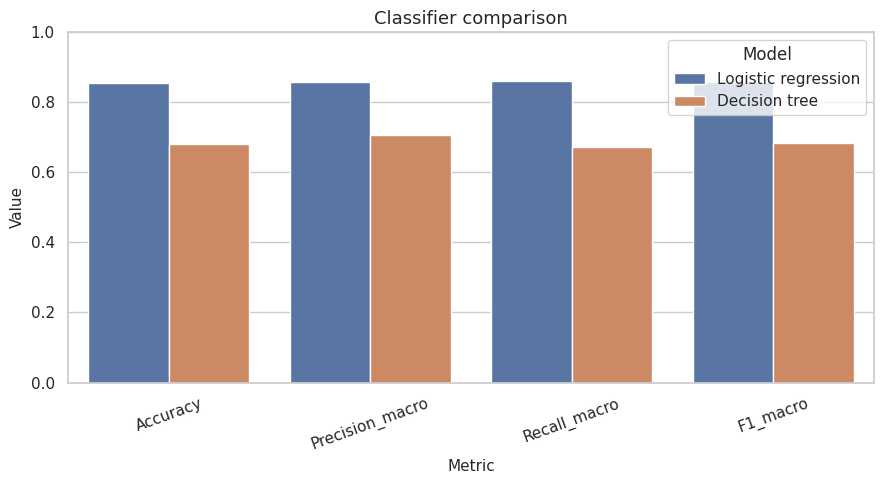

In [23]:
comparacion_larga = (
    comparacion_clasificadores.reset_index()
    .melt(id_vars="Model", var_name="Metric", value_name="Value")
)

ax = sns.barplot(data=comparacion_larga, x="Metric", y="Value", hue="Model")
ax.set(title="Classifier comparison", xlabel="Metric", ylabel="Value")
ax.set_ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 5.1 Check with cross-validation

In [24]:
cv_logistica = cross_val_score(
    modelo_logistico,
    X_clas,
    y_clas,
    cv=5,
    scoring="f1_macro",
)

cv_arbol = cross_val_score(
    modelo_arbol,
    X_clas,
    y_clas,
    cv=5,
    scoring="f1_macro",
)

resumen_cv = pd.DataFrame({
    "Model": ["Logistic regression", "Decision tree"],
    "F1_macro_mean": [cv_logistica.mean(), cv_arbol.mean()],
    "Std_deviation": [cv_logistica.std(), cv_arbol.std()],
})

resumen_cv.round(3)


,Model,F1_macro_mean,Std_deviation
0,Logistic regression,0.837,0.044
1,Decision tree,0.640,0.037


## Activity 5. Selecting the classifier

Write a recommendation of 120 to 180 words that answers:

- Which model obtained the best metrics on test?
- Does cross-validation support the same conclusion?
- Which one is easier to interpret?
- What errors appear in each confusion matrix?
- Which model would you choose to continue with and what would you improve before using it?

Do not choose a model based only on accuracy. Use at least three pieces of evidence.

**Answer — Activity 5**

I recommend continuing with **logistic regression**. On the test set it outperformed the decision tree: accuracy 0.856 versus 0.680 and macro F1 0.859 versus 0.685. Cross-validation supports this conclusion: average macro F1 of 0.837 (standard deviation 0.044) for logistic regression and 0.640 (0.037) for the tree, a gap much larger than the variation between folds. The tree is easier to explain through rules, although the coefficients of logistic regression can also be reviewed. In the confusion matrices, logistic regression classified 107 of 125 cases correctly and never confused Bajo (Low) with Alto (High); the tree got 85 right and labeled 12 high-risk cases as Medio (Medium), a costly error. Before using it, I would review the label: `Nivel_Riesgo` was built from clinical variables, so the performance is probably inflated. I would also tune hyperparameters and evaluate with more data.

# 6. Block D: clustering with K-means

## Modeling question

**Are there groups of patients with similar profiles without using `Nivel_Riesgo` as the response?**

K-means is an unsupervised model. During training it does not know the labels Bajo, Medio, or Alto. We will use only standardized numerical variables.

In [25]:
variables_cluster = [
    "Edad",
    "IMC",
    "Glucosa_mg_dL",
    "Presion_Sistolica_mmHg",
    "Colesterol_mg_dL",
    "Horas_Sueno",
    "Nivel_Estres",
    "Consultas_Medicas",
]

preprocesador_cluster = Pipeline(
    steps=[
        ("imputation", SimpleImputer(strategy="median")),
        ("scaling", StandardScaler()),
    ]
)

X_cluster = preprocesador_cluster.fit_transform(df[variables_cluster])
print("Clustering matrix:", X_cluster.shape)


Clustering matrix: (497, 8)


## 6.1 Selecting the number of clusters

In [26]:
resultados_k = []

for k in range(2, 7):
    modelo_k = KMeans(n_clusters=k, random_state=SEMILLA, n_init=20)
    etiquetas_k = modelo_k.fit_predict(X_cluster)
    resultados_k.append({
        "k": k,
        "inertia": modelo_k.inertia_,
        "silhouette": silhouette_score(X_cluster, etiquetas_k),
    })

tabla_k = pd.DataFrame(resultados_k)
tabla_k.round(3)


,k,inertia,silhouette
0,2,3233.402,0.182
1,3,2943.905,0.132
2,4,2677.846,0.145
3,5,2488.346,0.127
4,6,2348.753,0.118


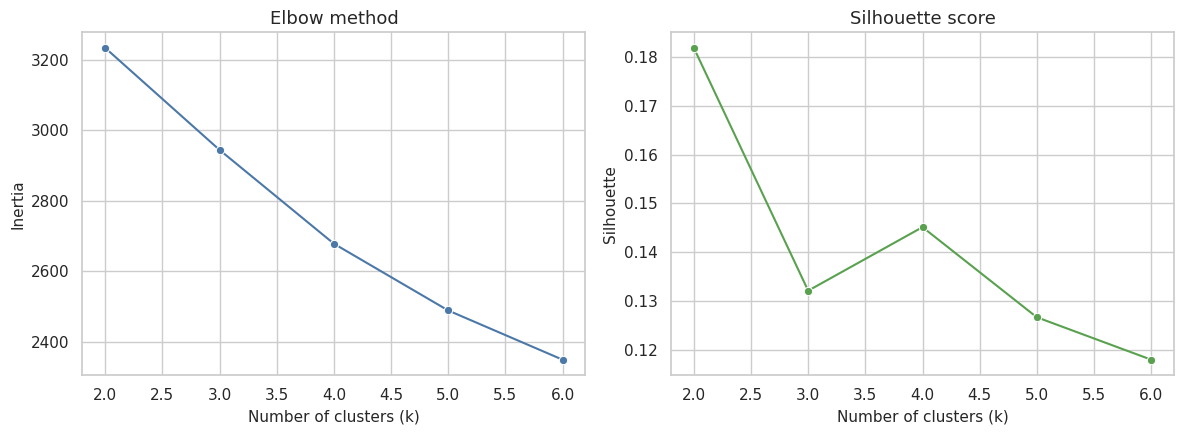

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.lineplot(data=tabla_k, x="k", y="inertia", marker="o", ax=axes[0], color="#4C78A8")
axes[0].set(title="Elbow method", xlabel="Number of clusters (k)", ylabel="Inertia")

sns.lineplot(data=tabla_k, x="k", y="silhouette", marker="o", ax=axes[1], color="#59A14F")
axes[1].set(title="Silhouette score", xlabel="Number of clusters (k)", ylabel="Silhouette")

plt.tight_layout()
plt.show()


## Activity 6. Choosing $k$

1. Where do you see the most important change in the inertia curve?
2. Which value of $k$ has the highest silhouette score?
3. Do the two pieces of evidence suggest the same solution?
4. What does a silhouette close to 1, to 0, or below 0 indicate?
5. Select a value of $k$ and justify your decision.

The following cell automatically chooses the highest silhouette to continue. You may replace `k_seleccionado` with another value if your argument justifies it.

**Answers — Activity 6**
1. Inertia decreases gradually with no clear elbow (slight bend at k = 4).
2. Highest silhouette: k = 2 (0.182).
3. They do not clearly agree: inertia always decreases as k increases.
4. ≈1: well-separated groups; ≈0: overlapping groups; <0: likely misassigned points.
5. k = 2: highest silhouette and the simplest solution to interpret (although 0.182 is low).

In [28]:
k_seleccionado = int(tabla_k.loc[tabla_k["silhouette"].idxmax(), "k"])
print("Selected k:", k_seleccionado)

modelo_kmeans = KMeans(
    n_clusters=k_seleccionado,
    random_state=SEMILLA,
    n_init=20,
)

df["Cluster"] = modelo_kmeans.fit_predict(X_cluster)
df["Cluster"].value_counts().sort_index()


Selected k: 2


,count
Cluster,
0,221
1,276


## 6.2 Cluster profile

In [29]:
perfil_clusters = df.groupby("Cluster")[variables_cluster].mean().round(2)
perfil_clusters


,Edad,IMC,Glucosa_mg_dL,Presion_Sistolica_mmHg,Colesterol_mg_dL,Horas_Sueno,Nivel_Estres,Consultas_Medicas
Cluster,,,,,,,,
0,58.85,29.37,114.21,131.76,208.00,7.04,5.59,3.44
1,38.58,25.46,97.18,116.48,173.81,6.97,5.56,1.99


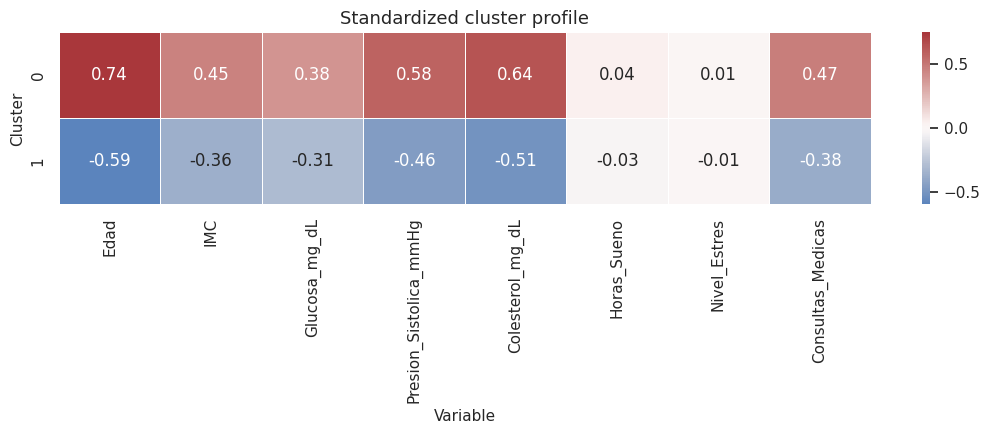

In [30]:
perfil_estandarizado = pd.DataFrame(
    X_cluster,
    columns=variables_cluster,
    index=df.index,
)
perfil_estandarizado["Cluster"] = df["Cluster"]
perfil_estandarizado = perfil_estandarizado.groupby("Cluster").mean()

plt.figure(figsize=(11, 4.5))
sns.heatmap(
    perfil_estandarizado,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    linewidths=0.5,
)
plt.title("Standardized cluster profile")
plt.xlabel("Variable")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()


## 6.3 Visualizing the clusters with PCA

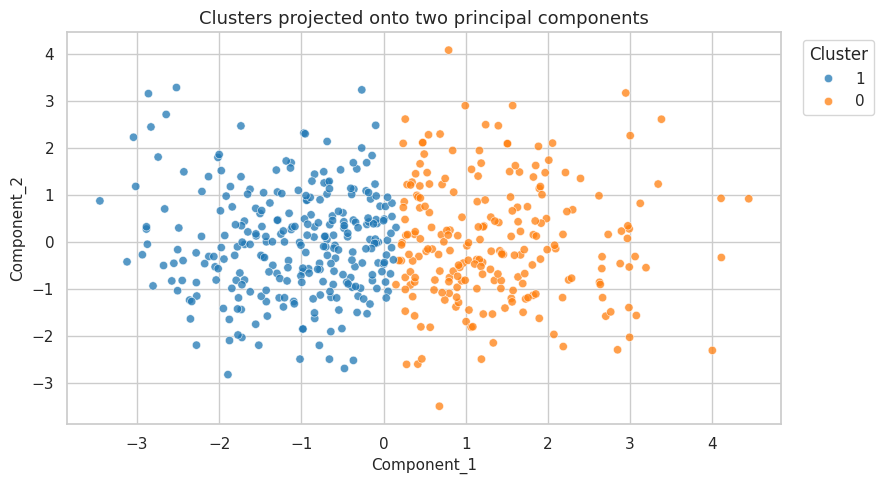

Variance explained by the two components: 0.454


In [31]:
pca = PCA(n_components=2, random_state=SEMILLA)
componentes = pca.fit_transform(X_cluster)

df_pca = pd.DataFrame({
    "Component_1": componentes[:, 0],
    "Component_2": componentes[:, 1],
    "Cluster": df["Cluster"].astype(str),
    "Nivel_Riesgo": df["Nivel_Riesgo"],
})

ax = sns.scatterplot(
    data=df_pca,
    x="Component_1",
    y="Component_2",
    hue="Cluster",
    palette="tab10",
    alpha=0.75,
)
ax.set(title="Clusters projected onto two principal components")
ax.legend(title="Cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

print("Variance explained by the two components:", round(pca.explained_variance_ratio_.sum(), 3))


## 6.4 Exploratory comparison with the risk level

This comparison is carried out **after** the clustering. `Nivel_Riesgo` did not participate in the training. The table serves to interpret whether the discovered groups have any relationship with the available label; it does not turn clustering into classification.

In [32]:
clusters_vs_riesgo = pd.crosstab(
    df["Cluster"],
    df["Nivel_Riesgo"],
    normalize="index",
).reindex(columns=["Bajo", "Medio", "Alto"]) * 100

clusters_vs_riesgo.round(1)


Nivel_Riesgo,Bajo,Medio,Alto
Cluster,,,
0,5.9,39.4,54.8
1,56.5,39.5,4.0


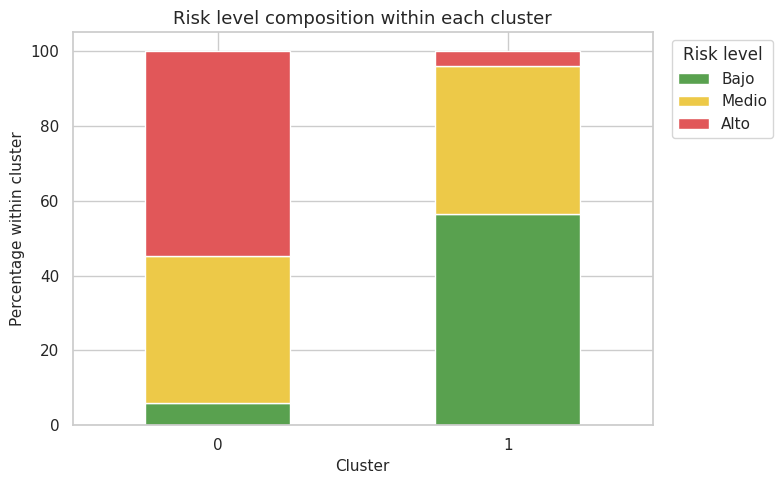

In [33]:
ax = clusters_vs_riesgo.plot(
    kind="bar",
    stacked=True,
    color=["#59A14F", "#EDC948", "#E15759"],
    figsize=(8, 5),
)
ax.set(
    title="Risk level composition within each cluster",
    xlabel="Cluster",
    ylabel="Percentage within cluster",
)
ax.legend(title="Risk level", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## Activity 7. Interpreting the clustering

1. Describe each cluster using at least four profile variables.
2. Propose a descriptive name for each group. Avoid clinical names that the dataset does not allow you to justify.
3. Do the clusters appear completely separated in the PCA projection?
4. What percentage of the variation do the two displayed components represent?
5. How does each cluster relate to `Nivel_Riesgo`?
6. Why would it make no sense to evaluate K-means with accuracy and a confusion matrix as if it were a classifier?
7. What limitations do you see in the obtained silhouette score?

**Answers — Activity 7** (Cluster 0 = 221 records; Cluster 1 = 276)
1. Cluster 0: older (58.9 years), BMI 29.4, glucose 114.2, blood pressure 131.8, cholesterol 208. Cluster 1: age 38.6, BMI 25.5, glucose 97.2, blood pressure 116.5, cholesterol 173.8.
2. Cluster 0: "older age, higher values". Cluster 1: "younger age, lower values".
3. They are not completely separated: there is overlap in the center of the projection.
4. The two components explain 45.4% of the variation.
5. Cluster 0: 54.8% high risk. Cluster 1: 56.5% low risk. The medium level is ~39% in both.
6. Cluster numbers are arbitrary and there is no label to compute accuracy against.
7. Low silhouette (0.182): weak structure and overlapping groups.

# 7. Synthesis: when is each model suitable?

Complete the following table in a text cell:

| Model | Task type | Target variable | When it is suitable | Metrics used | Observed limitation |
|---|---|---|---|---|---|
| Linear regression | | | | | |
| Logistic regression | | | | | |
| Decision tree | | | | | |
| K-means | | | | | |

**Summary table**

| Model | Task type | Target variable | When it is useful | Metrics used | Observed limitation |
|---|---|---|---|---|---|
| Linear regression | Regression | `Glucosa_mg_dL` | Estimating a numeric value; simple baseline | MAE, RMSE, R² | R² = 0.170 |
| Logistic regression | Classification | `Nivel_Riesgo` | Predicting categories with a simple model | Accuracy, precision, recall, F1, confusion matrix | Possibly inflated by how the label was created |
| Decision tree | Classification | `Nivel_Riesgo` | Explainable rules | Same as logistic + feature importance | Overfitting at greater depth |
| K-means | Unsupervised | None | Discovering profiles without labels | Inertia, silhouette | Silhouette 0.182 |

# 8. Conclusion of the activity

Write a conclusion of 180 to 250 words that answers:

- What practical difference did you find between regression, classification, and clustering?
- Which supervised model worked best and with what evidence?
- What did you learn from interpreting a confusion matrix?
- What did the cluster analysis contribute that the supervised models did not show?
- What would you improve in the data or in the models before a next phase?

The conclusion must be supported by the metrics obtained, not only by general opinions.

**Conclusion**

In practice, regression estimates a number (glucose), classification assigns a known category (`Nivel_Riesgo`), and clustering looks for groups without using labels. Linear regression performed modestly (MAE 12.4 mg/dL, RMSE 15.3, R² 0.170) and works as a baseline, not as a final model. Among the classifiers, logistic regression outperformed the decision tree (accuracy 0.856 versus 0.680; macro F1 0.859 versus 0.685), and cross-validation confirmed it (0.837 versus 0.640). Reading the confusion matrices taught me that accuracy hides the type of error: logistic regression got 107 of 125 cases right and never confused Bajo (Low) with Alto (High), while the tree labeled 12 high-risk cases as Medio (Medium). The tree also showed overfitting: its training accuracy rose from 0.632 to 0.884 as depth increased, while test accuracy stayed between 0.62 and 0.69. Clustering contributed two profiles (k = 2) differentiated by age, BMI, glucose, blood pressure, and cholesterol; the older group concentrates 54.8% of high risk and the other 56.5% of low risk, although with a low silhouette (0.182). I would improve the label, which was built from clinical variables and may inflate performance, tune hyperparameters, try nonlinear models, and use more data.